In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
!kaggle datasets download -d redzapdos123/indian-driving-dataset-detections-yolov11

Dataset URL: https://www.kaggle.com/datasets/redzapdos123/indian-driving-dataset-detections-yolov11
License(s): CC-BY-NC-SA-4.0
100% 20.5G/20.5G [04:38<00:00, 78.9MB/s]



In [ ]:
!unzip -q indian-driving-dataset-detections-yolov11.zip -d dataset

In [ ]:
import os
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

In [ ]:
DATASET_PATH = "/content/dataset"

In [ ]:
for root, dirs, files in os.walk(DATASET_PATH):
    print(root)

/content/dataset
/content/dataset/IDDDetectionsYOLODataset
/content/dataset/IDDDetectionsYOLODataset/train
/content/dataset/IDDDetectionsYOLODataset/train/labels
/content/dataset/IDDDetectionsYOLODataset/train/images
/content/dataset/IDDDetectionsYOLODataset/test
/content/dataset/IDDDetectionsYOLODataset/test/labels
/content/dataset/IDDDetectionsYOLODataset/test/images
/content/dataset/IDDDetectionsYOLODataset/val
/content/dataset/IDDDetectionsYOLODataset/val/labels
/content/dataset/IDDDetectionsYOLODataset/val/images


In [ ]:
yaml_path = os.path.join(DATASET_PATH, "IDDDetectionsYOLODataset", "data.yaml")

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

print(data)

{'path': 'IDDDetectionsYOLODataset/', 'names': ['animal', 'autorickshaw', 'bicycle', 'bus', 'car', 'caravan', 'motorcycle', 'person', 'rider', 'traffic light', 'traffic sign', 'trailer', 'train', 'truck', 'vehicle fallback'], 'nc': 15, 'test': 'test/images', 'train': 'train/images', 'val': 'val/images'}


In [ ]:
class_names = data["names"]

print(f"Total Classes : {len(class_names)}")

for i, cls in enumerate(class_names):
    print(i, cls)

Total Classes : 15
0 animal
1 autorickshaw
2 bicycle
3 bus
4 car
5 caravan
6 motorcycle
7 person
8 rider
9 traffic light
10 traffic sign
11 trailer
12 train
13 truck
14 vehicle fallback


In [ ]:
splits = ["train","val","test"]

for split in splits:

    img_path = Path(DATASET_PATH)/"IDDDetectionsYOLODataset"/split/"images"

    print(split,len(list(img_path.glob("*"))))

train 33569
val 4196
test 4197


In [ ]:
class_counter = Counter()

total_boxes = 0

for split in splits:

    label_path = Path(DATASET_PATH)/"IDDDetectionsYOLODataset"/split/"labels"

    for txt in label_path.glob("*.txt"):

        with open(txt) as f:

            for line in f:

                parts = line.split()

                if len(parts)!=5:
                    continue

                cls=int(parts[0])

                class_counter[cls]+=1

                total_boxes+=1

In [ ]:
df=pd.DataFrame({

    "Class ID":class_counter.keys(),

    "Class Name":[class_names[i] for i in class_counter.keys()],

    "Instances":class_counter.values()

})

df=df.sort_values("Instances",ascending=False)

df

,Class ID,Class Name,Instances
2,6,motorcycle,101758
3,8,rider,95466
1,4,car,90829
4,7,person,86353
6,1,autorickshaw,32086
5,13,truck,27765
7,14,vehicle fallback,20973
0,3,bus,18927
8,10,traffic sign,14515
9,0,animal,6106


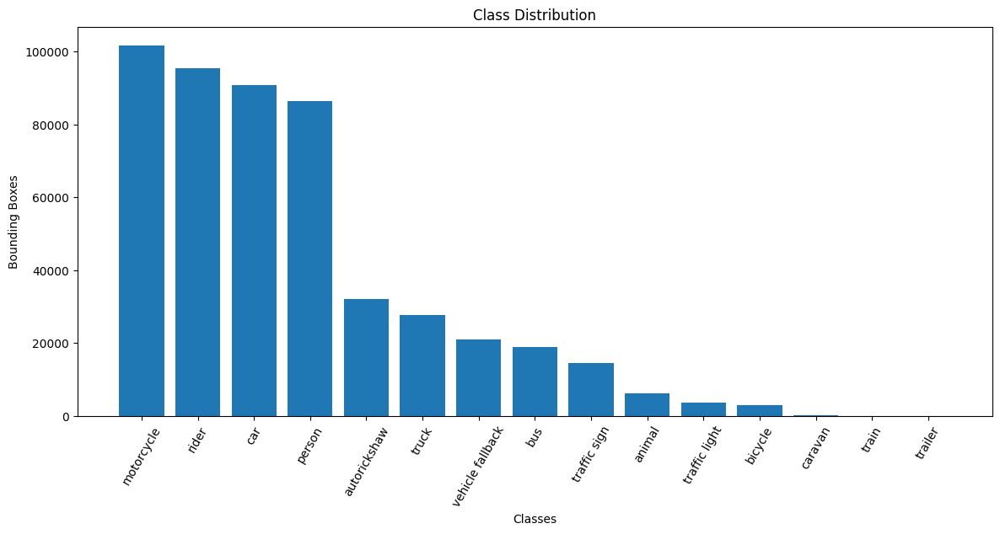

In [ ]:
plt.figure(figsize=(14,6))

plt.bar(df["Class Name"],df["Instances"])

plt.xticks(rotation=60)

plt.xlabel("Classes")

plt.ylabel("Bounding Boxes")

plt.title("Class Distribution")

plt.show()

In [ ]:
total_images = 0

for split in splits:
    total_images += len(list((Path(DATASET_PATH)/"IDDDetectionsYOLODataset"/split/"images").glob("*")))

print("="*50)
print("DATASET SUMMARY")
print("="*50)
print("Total Images:",total_images)
print("Total Bounding Boxes:",total_boxes)
print("Average Objects/Image:",round(total_boxes/total_images,2))
print("Total Classes:",len(class_names))

DATASET SUMMARY
Total Images: 41962
Total Bounding Boxes: 501777
Average Objects/Image: 11.96
Total Classes: 15


In [ ]:
import os
from pathlib import Path

OUTPUT_PATH = "/content/processed_dataset"

splits = ["train","val","test"]

for split in splits:

    os.makedirs(f"{OUTPUT_PATH}/{split}/images",exist_ok=True)

    os.makedirs(f"{OUTPUT_PATH}/{split}/labels",exist_ok=True)

print("Folders Created Successfully")

Folders Created Successfully


In [ ]:
for root,dirs,files in os.walk(OUTPUT_PATH):

    print(root)

/content/processed_dataset
/content/processed_dataset/train
/content/processed_dataset/train/labels
/content/processed_dataset/train/images
/content/processed_dataset/test
/content/processed_dataset/test/labels
/content/processed_dataset/test/images
/content/processed_dataset/val
/content/processed_dataset/val/labels
/content/processed_dataset/val/images


In [ ]:
KEEP_CLASSES = {
    4:0,      # car
    6:1,      # motorcycle
    3:2,      # bus
    13:3,     # truck
    1:4,      # autorickshaw
    2:5       # bicycle
}

In [ ]:
import shutil
from tqdm import tqdm

In [ ]:
SOURCE_PATH="/content/dataset/IDDDetectionsYOLODataset"

In [ ]:
print(os.listdir(SOURCE_PATH))

['ReadMe.md', 'data.yaml', 'license.md', 'train', 'test', 'val']


In [ ]:
from collections import Counter

new_class_counter = Counter()

removed_images = 0

kept_images = 0

removed_objects = 0

In [ ]:
from pathlib import Path
from collections import Counter
from tqdm import tqdm
import shutil
import os

# -------------------------------
# Class Mapping
# -------------------------------

KEEP_CLASSES = {
    4: 0,    # car
    6: 1,    # motorcycle
    3: 2,    # bus
    13: 3,   # truck
    1: 4,    # autorickshaw
    2: 5     # bicycle
}

NEW_CLASS_NAMES = [
    "car",
    "motorcycle",
    "bus",
    "truck",
    "autorickshaw",
    "bicycle"
]

new_class_counter = Counter()

kept_images = 0
removed_images = 0
removed_objects = 0

In [ ]:
SOURCE_PATH = "/content/dataset/IDDDetectionsYOLODataset"

OUTPUT_PATH = "/content/processed_dataset"

print(os.listdir(SOURCE_PATH))

['ReadMe.md', 'data.yaml', 'license.md', 'train', 'test', 'val']


In [ ]:
split = "train"

image_dir = Path(SOURCE_PATH) / split / "images"

label_dir = Path(SOURCE_PATH) / split / "labels"

out_img = Path(OUTPUT_PATH) / split / "images"

out_lbl = Path(OUTPUT_PATH) / split / "labels"

In [ ]:
for label_file in tqdm(list(label_dir.glob("*.txt"))):

    with open(label_file, "r") as f:
        lines = f.readlines()

    new_lines = []

    for line in lines:

        parts = line.strip().split()

        if len(parts) != 5:
            continue

        old_class = int(parts[0])

        if old_class in KEEP_CLASSES:

            new_class = KEEP_CLASSES[old_class]

            parts[0] = str(new_class)

            new_lines.append(" ".join(parts))

            new_class_counter[new_class] += 1

        else:

            removed_objects += 1

    # Skip images with no remaining objects
    if len(new_lines) == 0:

        removed_images += 1

        continue

    image_name = label_file.stem + ".jpg"

    image_path = image_dir / image_name

    # If image is png
    if not image_path.exists():

        image_path = image_dir / (label_file.stem + ".png")

    # If jpeg
    if not image_path.exists():

        image_path = image_dir / (label_file.stem + ".jpeg")

    if not image_path.exists():

        continue

    shutil.copy2(image_path, out_img / image_path.name)

    with open(out_lbl / label_file.name, "w") as f:

        f.write("\n".join(new_lines))

    kept_images += 1

100%|██████████| 33569/33569 [03:56<00:00, 141.85it/s]


In [ ]:
print("="*50)

print("TRAIN PROCESSING COMPLETE")

print("="*50)

print(f"Images Kept      : {kept_images}")

print(f"Images Removed   : {removed_images}")

print(f"Objects Removed  : {removed_objects}")

print("="*50)

TRAIN PROCESSING COMPLETE
Images Kept      : 30569
Images Removed   : 3000
Objects Removed  : 181959


In [ ]:
import pandas as pd

df_new = pd.DataFrame({

    "Class":NEW_CLASS_NAMES,

    "Instances":[new_class_counter[i] for i in range(len(NEW_CLASS_NAMES))]

})

df_new

,Class,Instances
0,car,72723
1,motorcycle,81650
2,bus,15191
3,truck,22212
4,autorickshaw,25517
5,bicycle,2482


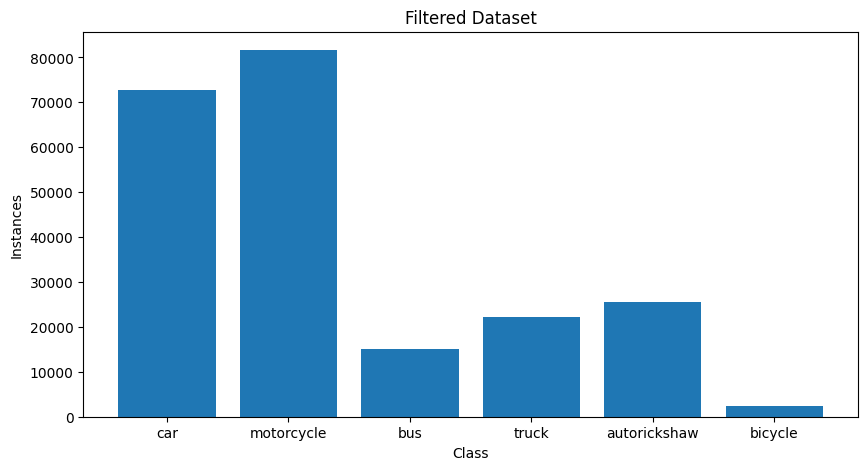

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(df_new["Class"],df_new["Instances"])

plt.title("Filtered Dataset")

plt.xlabel("Class")

plt.ylabel("Instances")

plt.show()

In [ ]:
print(len(os.listdir(out_img)))
print(len(os.listdir(out_lbl)))

30569
30569


In [ ]:
from pathlib import Path

train_img = Path("/content/processed_dataset/train/images")
train_lbl = Path("/content/processed_dataset/train/labels")

print("Images :", len(list(train_img.glob("*"))))
print("Labels :", len(list(train_lbl.glob("*.txt"))))

Images : 30569
Labels : 30569


In [ ]:
class_ids = set()

for file in train_lbl.glob("*.txt"):
    with open(file) as f:
        for line in f:
            class_ids.add(int(line.split()[0]))

print(class_ids)

{0, 1, 2, 3, 4, 5}


In [ ]:
empty = 0

for file in train_lbl.glob("*.txt"):
    if file.stat().st_size == 0:
        empty += 1

print("Empty Labels:", empty)

Empty Labels: 0


In [ ]:
bad_boxes = 0

for file in train_lbl.glob("*.txt"):
    with open(file) as f:
        for line in f:

            vals = list(map(float, line.split()[1:]))

            x,y,w,h = vals

            if not (0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 <= w <= 1 and
                    0 <= h <= 1):

                bad_boxes += 1

print("Invalid Boxes :", bad_boxes)

Invalid Boxes : 1


In [ ]:
from pathlib import Path

train_lbl = Path("/content/processed_dataset/train/labels")

for file in train_lbl.glob("*.txt"):

    with open(file) as f:

        for line_no, line in enumerate(f, start=1):

            parts = line.strip().split()

            if len(parts) != 5:
                print(f"Invalid format in {file.name}, line {line_no}")
                continue

            cls, x, y, w, h = map(float, parts)

            if not (0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 <= w <= 1 and
                    0 <= h <= 1):

                print("="*60)
                print("Invalid Annotation Found")
                print("="*60)
                print("File :", file)
                print("Line :", line_no)
                print("Annotation :", line.strip())

Invalid Annotation Found
File : /content/processed_dataset/train/labels/15-07-18-upload_0017291.txt
Line : 22
Annotation : 0 1.472266 1.348611 0.055469 0.302778


In [ ]:
from pathlib import Path

label_dir = Path("/content/processed_dataset/train/labels")

removed_invalid = 0

for file in label_dir.glob("*.txt"):

    valid_lines = []

    with open(file, "r") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) != 5:
                continue

            cls = parts[0]
            x, y, w, h = map(float, parts[1:])

            if (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < w <= 1 and
                0 < h <= 1
            ):
                valid_lines.append(line.strip())
            else:
                removed_invalid += 1

    with open(file, "w") as f:
        f.write("\n".join(valid_lines))

print("Removed Invalid Annotations:", removed_invalid)

Removed Invalid Annotations: 1


In [ ]:
bad_boxes = 0

for file in label_dir.glob("*.txt"):
    with open(file) as f:
        for line in f:

            cls, x, y, w, h = map(float, line.split())

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 <= w <= 1 and
                0 <= h <= 1
            ):
                bad_boxes += 1

print("Invalid Boxes:", bad_boxes)

Invalid Boxes: 0


In [ ]:
from pathlib import Path
from collections import Counter
import pandas as pd

label_dir = Path("/content/processed_dataset/train/labels")

image_stats = []

for label_file in label_dir.glob("*.txt"):

    counter = Counter()

    with open(label_file) as f:

        for line in f:

            cls = int(line.split()[0])

            counter[cls] += 1

    total_objects = sum(counter.values())

    dominant_class = counter.most_common(1)[0][0]

    image_stats.append({
        "image": label_file.stem,
        "objects": total_objects,
        "dominant": dominant_class
    })

df_images = pd.DataFrame(image_stats)

df_images.head()

,image,objects,dominant
0,BLR-2018-05-03_14-26-52_sideRight_right_0005480,4,2
1,BLR-2018-05-11_13-42-30_sideLeft_right_0001005,14,0
2,HYD-2018-06-11_13-14-41_frontNear_left_0006285,22,1
3,HYD-2018-06-11_13-54-41_0006851,17,1
4,BLR-2018-04-19_18-06-55_frontNear_000192_r,1,3


In [ ]:
dominant_distribution = df_images["dominant"].value_counts().sort_index()

dominant_distribution

,count
dominant,
0,10666
1,12738
2,2056
3,3010
4,1763
5,336


In [ ]:
import os

FINAL_PATH = "/content/final_dataset"

for split in ["train", "val", "test"]:
    os.makedirs(f"{FINAL_PATH}/{split}/images", exist_ok=True)
    os.makedirs(f"{FINAL_PATH}/{split}/labels", exist_ok=True)

print("Final Dataset Structure Created")

Final Dataset Structure Created


In [ ]:
TARGET_IMAGES = 15000

sampling_plan = (
    dominant_distribution / dominant_distribution.sum() * TARGET_IMAGES
).round().astype(int)

sampling_plan

,count
dominant,
0,5234
1,6250
2,1009
3,1477
4,865
5,165


In [ ]:
sampling_df = pd.DataFrame({
    "Class": [
        "Car",
        "Motorcycle",
        "Bus",
        "Truck",
        "Autorickshaw",
        "Bicycle"
    ],
    "Available": dominant_distribution.values,
    "Sample": sampling_plan.values
})

sampling_df

,Class,Available,Sample
0,Car,10666,5234
1,Motorcycle,12738,6250
2,Bus,2056,1009
3,Truck,3010,1477
4,Autorickshaw,1763,865
5,Bicycle,336,165


In [ ]:
import random

random.seed(42)

sampled_images = []

for cls in sampling_plan.index:

    cls_images = df_images[df_images["dominant"] == cls]

    n = min(sampling_plan[cls], len(cls_images))

    sampled = cls_images.sample(
        n=n,
        random_state=42
    )

    sampled_images.extend(sampled["image"].tolist())

print("Selected Images:", len(sampled_images))

Selected Images: 15000


In [ ]:
import shutil
from pathlib import Path
from tqdm import tqdm

SRC_IMG = Path("/content/processed_dataset/train/images")
SRC_LBL = Path("/content/processed_dataset/train/labels")

DST_IMG = Path("/content/final_dataset/train/images")
DST_LBL = Path("/content/final_dataset/train/labels")

copied = 0

for img_name in tqdm(sampled_images):

    found = False

    for ext in [".jpg", ".jpeg", ".png"]:

        src_img = SRC_IMG / (img_name + ext)

        if src_img.exists():

            shutil.copy2(src_img, DST_IMG / src_img.name)

            found = True

            break

    if not found:
        continue

    src_lbl = SRC_LBL / (img_name + ".txt")

    shutil.copy2(src_lbl, DST_LBL / src_lbl.name)

    copied += 1

print(f"Copied {copied} images and labels.")

100%|██████████| 15000/15000 [01:43<00:00, 144.82it/s]

Copied 15000 images and labels.


In [ ]:
from pathlib import Path

final_img = Path("/content/final_dataset/train/images")
final_lbl = Path("/content/final_dataset/train/labels")

print("Images:", len(list(final_img.glob("*"))))
print("Labels:", len(list(final_lbl.glob("*.txt"))))

Images: 15000
Labels: 15000


In [ ]:
from pathlib import Path

for split in ["val", "test"]:
    print(
        split,
        "images:", len(list(Path(SOURCE_PATH, split, "images").glob("*"))),
        "labels:", len(list(Path(SOURCE_PATH, split, "labels").glob("*.txt")))
    )

val images: 4196 labels: 4196
test images: 4197 labels: 4197


In [ ]:
import pandas as pd
from pathlib import Path
from collections import Counter

def analyze_split(split):

    label_dir = Path("/content/processed_dataset") / split / "labels"

    image_stats = []

    for label_file in label_dir.glob("*.txt"):

        counter = Counter()

        with open(label_file, "r") as f:

            for line in f:

                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                cls = int(parts[0])
                counter[cls] += 1

        if not counter:
            continue

        total_objects = sum(counter.values())

        dominant_class = counter.most_common(1)[0][0]

        image_stats.append({
            "image": label_file.stem,
            "objects": total_objects,
            "dominant": dominant_class
        })

    return pd.DataFrame(image_stats)

In [ ]:
import pandas as pd
from pathlib import Path
from collections import Counter

# Original analyze_split function in cell 2L2EqDkXdCmA uses Path("/content/processed_dataset").
# Since 'val' data is not yet in processed_dataset, analyze_split("val") currently returns an empty DataFrame.
# To fix the KeyError: 'dominant', we need to analyze 'val' data from the SOURCE_PATH.
# We will effectively re-implement the logic of analyze_split here for 'val' split
# but pointing to SOURCE_PATH, which contains the original unprocessed 'val' data.

split_name = "val"
label_dir_for_val = Path(SOURCE_PATH) / split_name / "labels" # Use SOURCE_PATH here

image_stats_for_val = []

for label_file in label_dir_for_val.glob("*.txt"):
    counter = Counter()
    with open(label_file, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            # For original data, count the classes as they are.
            # The class remapping (KEEP_CLASSES) was part of the processing step
            # for the 'train' split into OUTPUT_PATH, not part of the 'analyze_split' function itself.
            cls = int(parts[0])
            counter[cls] += 1

    if not counter:
        continue # Skip if no valid annotations in this file

    total_objects = sum(counter.values())
    # Ensure there are objects to avoid error if counter becomes empty after some unhandled filtering edge case.
    # Though in this case (no filtering), it should always have objects if counter is not empty.
    if total_objects > 0:
        dominant_class = counter.most_common(1)[0][0]
        image_stats_for_val.append({
            "image": label_file.stem,
            "objects": total_objects,
            "dominant": dominant_class
        })

val_df = pd.DataFrame(image_stats_for_val)

print("Validation images:", len(val_df))

# Only proceed to calculate val_distribution if val_df is not empty
if not val_df.empty:
    val_distribution = (
        val_df["dominant"]
        .value_counts()
        .sort_index()
    )
    print(val_distribution)
else:
    print("No dominant class data could be extracted for the 'val' split. The DataFrame is empty.")

Validation images: 4187
dominant
0     112
1     146
2      29
3     184
4     954
5       2
6     795
7     804
8     598
9      12
10    169
12      1
13    247
14    134
Name: count, dtype: int64


In [ ]:
import pandas as pd
from pathlib import Path
from collections import Counter

# Similar to the 'val' split, the 'test' split labels are still in SOURCE_PATH.
# We will re-implement the logic of analyze_split here for the 'test' split,
# pointing to SOURCE_PATH.

split_name = "test"
label_dir_for_test = Path(SOURCE_PATH) / split_name / "labels" # Use SOURCE_PATH here

image_stats_for_test = []

for label_file in label_dir_for_test.glob("*.txt"):
    counter = Counter()
    with open(label_file, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            cls = int(parts[0])
            counter[cls] += 1

    if not counter:
        continue # Skip if no valid annotations in this file

    total_objects = sum(counter.values())
    if total_objects > 0:
        dominant_class = counter.most_common(1)[0][0]
        image_stats_for_test.append({
            "image": label_file.stem,
            "objects": total_objects,
            "dominant": dominant_class
        })

test_df = pd.DataFrame(image_stats_for_test)

print("Test images:", len(test_df))

# Only proceed to calculate test_distribution if test_df is not empty
if not test_df.empty:
    test_distribution = (
        test_df["dominant"]
        .value_counts()
        .sort_index()
    )
    print(test_distribution)
else:
    print("No dominant class data could be extracted for the 'test' split. The DataFrame is empty.")

Test images: 4190
dominant
0      96
1     106
2      26
3     204
4     987
5       1
6     817
7     815
8     552
9      16
10    150
12      2
13    276
14    142
Name: count, dtype: int64


In [ ]:
from pathlib import Path
# shutil and tqdm are already imported in a previous cell and are available.

CLASS_MAPPING = {
    4: 0,    # car
    6: 1,    # motorcycle
    3: 2,    # bus
    13: 3,   # truck
    1: 4,    # autorickshaw
    2: 5     # bicycle
}

def clean_and_remap_split(split_name):
    # Input directories (read from SOURCE_PATH)
    source_image_dir = Path(SOURCE_PATH) / split_name / "images"
    source_label_dir = Path(SOURCE_PATH) / split_name / "labels"

    # Output directories (write to OUTPUT_PATH)
    output_image_dir = Path(OUTPUT_PATH) / split_name / "images"
    output_label_dir = Path(OUTPUT_PATH) / split_name / "labels"

    # Ensure output directories exist (these were already created in DeGLT5RzXocv, but good practice)
    output_image_dir.mkdir(parents=True, exist_ok=True)
    output_label_dir.mkdir(parents=True, exist_ok=True)

    total_annotations = 0
    kept_annotations = 0
    removed_annotations = 0
    kept_images_count = 0
    removed_images_count = 0

    # Using tqdm for progress bar
    # `list()` converts the glob iterator to a list, allowing tqdm to determine total length.
    for label_file in tqdm(list(source_label_dir.glob("*.txt")), desc=f"Processing {split_name} labels"):
        new_lines = []

        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) != 5:
                    removed_annotations += 1
                    continue

                old_class = int(parts[0])
                total_annotations += 1

                # Keep only our six target classes
                if old_class not in CLASS_MAPPING:
                    removed_annotations += 1
                    continue

                new_class = CLASS_MAPPING[old_class]
                x, y, w, h = map(float, parts[1:])

                # Validate bounding box (0 < w <= 1 and 0 < h <= 1 for non-empty boxes)
                if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
                    removed_annotations += 1
                    continue

                new_lines.append(f"{new_class} {x} {y} {w} {h}")
                kept_annotations += 1

        # If after processing, no valid annotations remain for an image,
        # we consider that image "removed" for this filtered dataset.
        if not new_lines:
            removed_images_count += 1
            continue # Skip copying image and writing empty label file

        # Find and copy the corresponding image
        image_name_stem = label_file.stem
        image_path_found = False
        image_to_copy_src = None

        for ext in [".jpg", ".jpeg", ".png"]:
            potential_image_path = source_image_dir / (image_name_stem + ext)
            if potential_image_path.exists():
                image_to_copy_src = potential_image_path
                image_path_found = True
                break

        if image_path_found:
            shutil.copy2(image_to_copy_src, output_image_dir / image_to_copy_src.name)
            kept_images_count += 1
            # Write the cleaned labels to the output directory
            with open(output_label_dir / label_file.name, "w") as f:
                f.write("\n".join(new_lines))
        else:
            # This case means a label file exists but its corresponding image doesn't.
            # This shouldn't happen with a consistent dataset, but we handle it by removing the image.
            removed_images_count += 1
            print(f"Warning: Image not found for label file {label_file.name}. Skipping image and its processed labels.")


    print(f"\n===== {split_name.upper()} SUMMARY =====")
    print(f"Total label files in source     : {len(list(source_label_dir.glob('*.txt')))}")
    print(f"Images Kept (with valid labels) : {kept_images_count}")
    print(f"Images Removed (no valid labels/image not found) : {removed_images_count}")
    print(f"Total annotations in source     : {total_annotations}")
    print(f"Kept annotations                : {kept_annotations}")
    print(f"Removed annotations             : {removed_annotations}")


clean_and_remap_split("val")
clean_and_remap_split("test")

Processing val labels: 100%|██████████| 4196/4196 [00:32<00:00, 130.54it/s]



===== VAL SUMMARY =====
Total label files in source     : 4196
Images Kept (with valid labels) : 3791
Images Removed (no valid labels/image not found) : 405
Total annotations in source     : 49838
Kept annotations                : 26910
Removed annotations             : 22928


Processing test labels: 100%|██████████| 4197/4197 [00:26<00:00, 157.20it/s]



===== TEST SUMMARY =====
Total label files in source     : 4197
Images Kept (with valid labels) : 3822
Images Removed (no valid labels/image not found) : 375
Total annotations in source     : 50205
Kept annotations                : 27753
Removed annotations             : 22452


In [ ]:
from collections import Counter
from pathlib import Path
import pandas as pd

def analyze_clean_split(split):

    label_dir = Path("/content/processed_dataset") / split / "labels"

    image_stats = []

    for label_file in label_dir.glob("*.txt"):

        counter = Counter()

        with open(label_file, "r") as f:

            for line in f:

                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                cls = int(parts[0])

                # Only 0-5 should now exist
                if cls in range(6):
                    counter[cls] += 1

        # Skip images with no target objects
        if not counter:
            continue

        total_objects = sum(counter.values())

        dominant_class = counter.most_common(1)[0][0]

        image_stats.append({
            "image": label_file.stem,
            "objects": total_objects,
            "dominant": dominant_class
        })

    return pd.DataFrame(image_stats)


val_df = analyze_clean_split("val")
test_df = analyze_clean_split("test")

val_distribution = (
    val_df["dominant"]
    .value_counts()
    .sort_index()
)

test_distribution = (
    test_df["dominant"]
    .value_counts()
    .sort_index()
)

print("========== VALIDATION ==========")
print("Usable images:", len(val_df))
print(val_distribution)

print("\n========== TEST ==========")
print("Usable images:", len(test_df))
print(test_distribution)

========== VALIDATION ==========
Usable images: 3791
dominant
0    1319
1    1550
2     247
3     374
4     251
5      50
Name: count, dtype: int64

========== TEST ==========
Usable images: 3822
dominant
0    1328
1    1518
2     288
3     390
4     242
5      56
Name: count, dtype: int64


In [ ]:
VAL_TARGET = 2000
TEST_TARGET = 2000

RANDOM_STATE = 42

In [ ]:
import pandas as pd

def stratified_sample_with_rare_class(
    df,
    target_size,
    rare_class=5,
    random_state=42
):

    # Separate rare class
    rare_df = df[df["dominant"] == rare_class]

    # Other classes
    common_df = df[df["dominant"] != rare_class]

    # Keep ALL rare-class images
    rare_count = len(rare_df)

    # Remaining slots
    remaining = target_size - rare_count

    # Distribution of common classes
    class_counts = common_df["dominant"].value_counts().sort_index()

    # Initial proportional allocation
    raw_samples = (
        class_counts / class_counts.sum()
    ) * remaining

    sample_counts = raw_samples.floor().astype(int)

    # Handle rounding
    leftover = remaining - sample_counts.sum()

    remainders = (
        raw_samples - sample_counts
    ).sort_values(ascending=False)

    for cls in remainders.index[:leftover]:
        sample_counts[cls] += 1

    print("\nSampling plan:")
    print(sample_counts)

    print(f"\nRare class {rare_class} images kept:", rare_count)
    print("Total target:", target_size)

    # Select rare images
    selected = [
        rare_df
    ]

    # Select common classes
    for cls, n in sample_counts.items():

        class_df = common_df[
            common_df["dominant"] == cls
        ]

        sampled = class_df.sample(
            n=min(n, len(class_df)),
            random_state=random_state
        )

        selected.append(sampled)

    # Combine
    result = pd.concat(
        selected,
        ignore_index=True
    )

    # Shuffle
    result = result.sample(
        frac=1,
        random_state=random_state
    ).reset_index(drop=True)

    return result

In [ ]:
import pandas as pd
import numpy as np

def stratified_sample_with_rare_class(
    df,
    target_size,
    rare_class=5,
    random_state=42
):
    # Separate rare class
    rare_df = df[df["dominant"] == rare_class]
    # Other classes
    common_df = df[df["dominant"] != rare_class]
    # Keep ALL rare-class images
    rare_count = len(rare_df)
    # Remaining slots
    remaining = target_size - rare_count
    # Distribution of common classes
    class_counts = common_df["dominant"].value_counts().sort_index()
    # Initial proportional allocation
    raw_samples = (
        class_counts / class_counts.sum()
    ) * remaining
    # Fix: Use np.floor() instead of Series.floor()
    sample_counts = np.floor(raw_samples).astype(int)
    # Handle rounding
    leftover = remaining - sample_counts.sum()
    remainders = (
        raw_samples - sample_counts
    ).sort_values(ascending=False)
    for cls in remainders.index[:leftover]:
        sample_counts[cls] += 1
    print("\nSampling plan:")
    print(sample_counts)
    print(f"\nRare class {rare_class} images kept:", rare_count)
    print("Total target:", target_size)
    # Select rare images
    selected = [
        rare_df
    ]
    # Select common classes
    for cls, n in sample_counts.items():
        class_df = common_df[
            common_df["dominant"] == cls
        ]
        sampled = class_df.sample(
            n=min(n, len(class_df)),
            random_state=random_state
        )
        selected.append(sampled)
    # Combine
    result = pd.concat(
        selected,
        ignore_index=True
    )
    # Shuffle
    result = result.sample(
        frac=1,
        random_state=random_state
    ).reset_index(drop=True)
    return result

val_sampled = stratified_sample_with_rare_class(
    val_df,
    VAL_TARGET,
    rare_class=5,
    random_state=42
)

print("\nValidation selected:", len(val_sampled))

print(
    val_sampled["dominant"]
    .value_counts()
    .sort_index()
)


Sampling plan:
dominant
0    687
1    808
2    129
3    195
4    131
Name: count, dtype: int64

Rare class 5 images kept: 50
Total target: 2000

Validation selected: 2000
dominant
0    687
1    808
2    129
3    195
4    131
5     50
Name: count, dtype: int64


In [ ]:
test_sampled = stratified_sample_with_rare_class(
    test_df,
    TEST_TARGET,
    rare_class=5,
    random_state=42
)

print("\nTest selected:", len(test_sampled))

print(
    test_sampled["dominant"]
    .value_counts()
    .sort_index()
)


Sampling plan:
dominant
0    685
1    784
2    149
3    201
4    125
Name: count, dtype: int64

Rare class 5 images kept: 56
Total target: 2000

Test selected: 2000
dominant
0    685
1    784
2    149
3    201
4    125
5     56
Name: count, dtype: int64


In [ ]:
import shutil
from pathlib import Path
from tqdm import tqdm

def copy_selected_split(
    split,
    sampled_df
):

    source_images = Path(
        f"/content/processed_dataset/{split}/images"
    )

    source_labels = Path(
        f"/content/processed_dataset/{split}/labels"
    )

    destination_images = Path(
        f"/content/final_dataset/{split}/images"
    )

    destination_labels = Path(
        f"/content/final_dataset/{split}/labels"
    )

    destination_images.mkdir(
        parents=True,
        exist_ok=True
    )

    destination_labels.mkdir(
        parents=True,
        exist_ok=True
    )

    copied = 0
    missing = 0

    for image_id in tqdm(
        sampled_df["image"],
        desc=f"Copying {split}"
    ):

        # Find image
        image_found = False

        for extension in [
            ".jpg",
            ".jpeg",
            ".png",
            ".JPG",
            ".JPEG",
            ".PNG"
        ]:

            source_image = (
                source_images /
                f"{image_id}{extension}"
            )

            if source_image.exists():

                shutil.copy2(
                    source_image,
                    destination_images /
                    source_image.name
                )

                image_found = True
                break

        if not image_found:
            missing += 1
            continue

        # Copy label
        source_label = (
            source_labels /
            f"{image_id}.txt"
        )

        if source_label.exists():

            shutil.copy2(
                source_label,
                destination_labels /
                source_label.name
            )

            copied += 1

        else:
            missing += 1

    print(f"\n===== {split.upper()} COPY SUMMARY =====")
    print("Copied:", copied)
    print("Missing:", missing)


copy_selected_split("val", val_sampled)

copy_selected_split("test", test_sampled)

Copying val: 100%|██████████| 2000/2000 [00:13<00:00, 148.49it/s]



===== VAL COPY SUMMARY =====
Copied: 2000
Missing: 0


Copying test: 100%|██████████| 2000/2000 [00:10<00:00, 199.47it/s]


===== TEST COPY SUMMARY =====
Copied: 2000
Missing: 0


In [ ]:
from pathlib import Path

for split in ["train", "val", "test"]:

    image_dir = Path(
        f"/content/final_dataset/{split}/images"
    )

    label_dir = Path(
        f"/content/final_dataset/{split}/labels"
    )

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    print(
        f"{split.upper():5} | "
        f"Images: {len(images):5} | "
        f"Labels: {len(labels):5}"
    )

TRAIN | Images: 15000 | Labels: 15000
VAL   | Images:  2000 | Labels:  2000
TEST  | Images:  2000 | Labels:  2000


In [ ]:
from pathlib import Path

BASE = Path("/content/final_dataset")

for split in ["train", "val", "test"]:

    image_dir = BASE / split / "images"
    label_dir = BASE / split / "labels"

    image_stems = {
        p.stem for p in image_dir.iterdir()
        if p.is_file()
    }

    label_stems = {
        p.stem for p in label_dir.glob("*.txt")
    }

    missing_labels = image_stems - label_stems
    missing_images = label_stems - image_stems

    print(f"\n===== {split.upper()} =====")

    print("Images:", len(image_stems))
    print("Labels:", len(label_stems))

    print("Images without labels:", len(missing_labels))
    print("Labels without images:", len(missing_images))


===== TRAIN =====
Images: 15000
Labels: 15000
Images without labels: 0
Labels without images: 0

===== VAL =====
Images: 2000
Labels: 2000
Images without labels: 0
Labels without images: 0

===== TEST =====
Images: 2000
Labels: 2000
Images without labels: 0
Labels without images: 0


In [ ]:
from pathlib import Path

NUM_CLASSES = 6

invalid_boxes = []
invalid_classes = []
empty_labels = []

for split in ["train", "val", "test"]:

    label_dir = BASE / split / "labels"

    for label_file in label_dir.glob("*.txt"):

        with open(label_file, "r") as f:
            lines = [line.strip() for line in f if line.strip()]

        if len(lines) == 0:
            empty_labels.append(
                (split, label_file.name)
            )
            continue

        for line_no, line in enumerate(lines, start=1):

            parts = line.split()

            if len(parts) != 5:
                invalid_boxes.append(
                    (split, label_file.name, line_no, line)
                )
                continue

            try:
                cls, x, y, w, h = map(float, parts)
            except:
                invalid_boxes.append(
                    (split, label_file.name, line_no, line)
                )
                continue

            # Check class
            if cls != int(cls) or not (0 <= cls < NUM_CLASSES):
                invalid_classes.append(
                    (split, label_file.name, line_no, cls)
                )

            # Check YOLO normalized coordinates
            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < w <= 1 and
                0 < h <= 1
            ):
                invalid_boxes.append(
                    (split, label_file.name, line_no, line)
                )

print("========== ANNOTATION QC ==========")

print("Invalid boxes:", len(invalid_boxes))
print("Invalid classes:", len(invalid_classes))
print("Empty label files:", len(empty_labels))

========== ANNOTATION QC ==========
Invalid boxes: 0
Invalid classes: 0
Empty label files: 0


In [ ]:
from PIL import Image
from tqdm import tqdm

corrupted_images = []

for split in ["train", "val", "test"]:

    image_dir = BASE / split / "images"

    image_files = list(image_dir.iterdir())

    for image_file in tqdm(
        image_files,
        desc=f"Checking {split}"
    ):

        try:
            with Image.open(image_file) as img:
                img.verify()

        except Exception as e:

            corrupted_images.append(
                (split, image_file.name, str(e))
            )

print("\n========== IMAGE QC ==========")
print("Corrupted images:", len(corrupted_images))

if corrupted_images:
    print("\nFirst few corrupted files:")
    for item in corrupted_images[:10]:
        print(item)

Checking test: 100%|██████████| 2000/2000 [00:00<00:00, 8094.04it/s]


========== IMAGE QC ==========
Corrupted images: 0


In [ ]:
from collections import Counter

class_names = {
    0: "car",
    1: "motorcycle",
    2: "bus",
    3: "truck",
    4: "autorickshaw",
    5: "bicycle"
}

for split in ["train", "val", "test"]:

    counter = Counter()

    label_dir = BASE / split / "labels"

    for label_file in label_dir.glob("*.txt"):

        with open(label_file, "r") as f:

            for line in f:

                parts = line.strip().split()

                if len(parts) == 5:

                    cls = int(float(parts[0]))
                    counter[cls] += 1

    print(f"\n========== {split.upper()} ==========")

    total = sum(counter.values())

    print("Total bounding boxes:", total)

    for cls in range(6):

        count = counter[cls]

        percentage = (
            count / total * 100
            if total > 0 else 0
        )

        print(
            f"{cls} | "
            f"{class_names[cls]:12} | "
            f"{count:7} | "
            f"{percentage:6.2f}%"
        )


========== TRAIN ==========
Total bounding boxes: 107354
0 | car          |   35334 |  32.91%
1 | motorcycle   |   40084 |  37.34%
2 | bus          |    7354 |   6.85%
3 | truck        |   10945 |  10.20%
4 | autorickshaw |   12432 |  11.58%
5 | bicycle      |    1205 |   1.12%

========== VAL ==========
Total bounding boxes: 14291
0 | car          |    4601 |  32.20%
1 | motorcycle   |    5351 |  37.44%
2 | bus          |     965 |   6.75%
3 | truck        |    1471 |  10.29%
4 | autorickshaw |    1705 |  11.93%
5 | bicycle      |     198 |   1.39%

========== TEST ==========
Total bounding boxes: 14759
0 | car          |    4840 |  32.79%
1 | motorcycle   |    5426 |  36.76%
2 | bus          |    1032 |   6.99%
3 | truck        |    1470 |   9.96%
4 | autorickshaw |    1810 |  12.26%
5 | bicycle      |     181 |   1.23%


In [ ]:
yaml_content = """
path: /content/final_dataset

train: train/images
val: val/images
test: test/images

nc: 6

names:
  0: car
  1: motorcycle
  2: bus
  3: truck
  4: autorickshaw
  5: bicycle
"""

yaml_path = BASE / "data.yaml"

with open(yaml_path, "w") as f:
    f.write(yaml_content.strip())

print("data.yaml created successfully:")
print(yaml_path)

print("\n")
print(yaml_content)

data.yaml created successfully:
/content/final_dataset/data.yaml



path: /content/final_dataset

train: train/images
val: val/images
test: test/images

nc: 6

names:
  0: car
  1: motorcycle
  2: bus
  3: truck
  4: autorickshaw
  5: bicycle



In [ ]:
import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path("/content/final_dataset")

class_names = {
    0: "car",
    1: "motorcycle",
    2: "bus",
    3: "truck",
    4: "autorickshaw",
    5: "bicycle"
}

print("Visualization setup complete.")

Visualization setup complete.


In [ ]:
def visualize_random_images(
    split="train",
    num_images=6,
    seed=42
):

    random.seed(seed)

    image_dir = BASE / split / "images"
    label_dir = BASE / split / "labels"

    image_files = list(image_dir.iterdir())

    selected_images = random.sample(
        image_files,
        min(num_images, len(image_files))
    )

    for image_file in selected_images:

        label_file = label_dir / f"{image_file.stem}.txt"

        image = cv2.imread(str(image_file))

        if image is None:
            print("Could not read:", image_file.name)
            continue

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        height, width = image.shape[:2]

        if label_file.exists():

            with open(label_file, "r") as f:
                lines = f.readlines()

            for line in lines:

                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                cls, x, y, w, h = map(
                    float,
                    parts
                )

                cls = int(cls)

                # Convert YOLO coordinates
                x1 = int((x - w / 2) * width)
                y1 = int((y - h / 2) * height)

                x2 = int((x + w / 2) * width)
                y2 = int((y + h / 2) * height)

                # Keep coordinates inside image
                x1 = max(0, x1)
                y1 = max(0, y1)
                x2 = min(width - 1, x2)
                y2 = min(height - 1, y2)

                # Draw bounding box
                cv2.rectangle(
                    image,
                    (x1, y1),
                    (x2, y2),
                    (255, 0, 0),
                    2
                )

                # Label
                label = class_names.get(
                    cls,
                    f"class_{cls}"
                )

                cv2.putText(
                    image,
                    label,
                    (x1, max(20, y1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (255, 0, 0),
                    2
                )

        plt.figure(figsize=(12, 7))
        plt.imshow(image)
        plt.title(
            f"{split.upper()} — {image_file.name}"
        )
        plt.axis("off")
        plt.show()

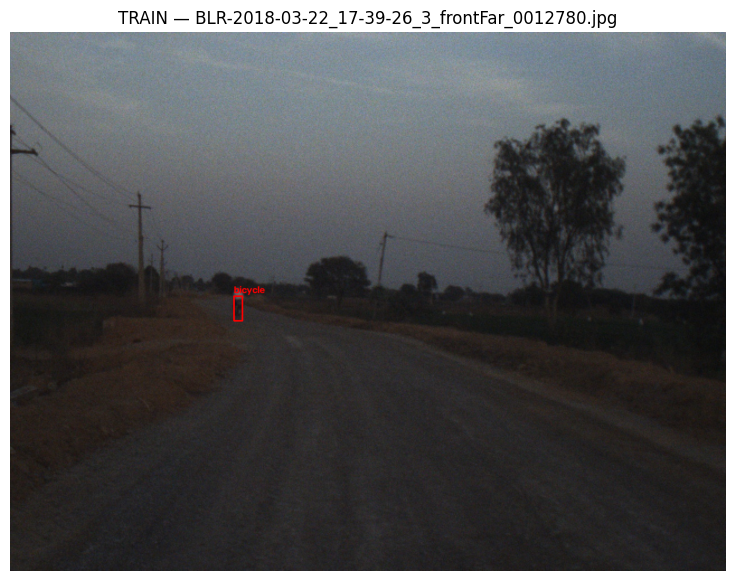

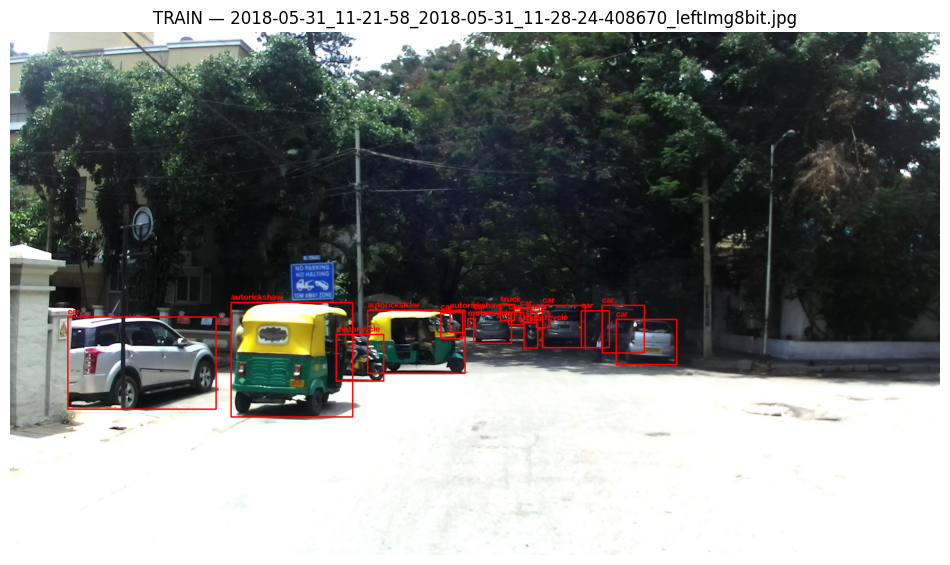

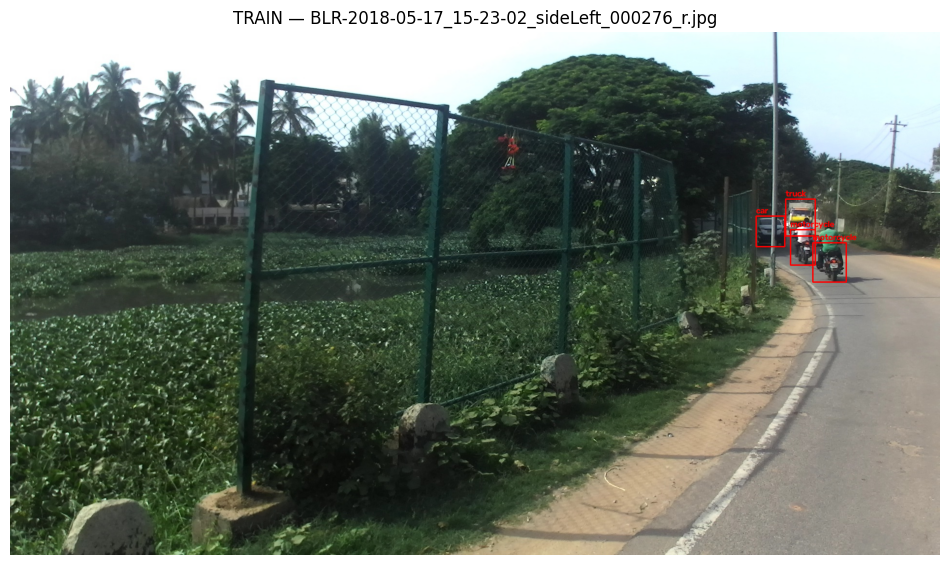

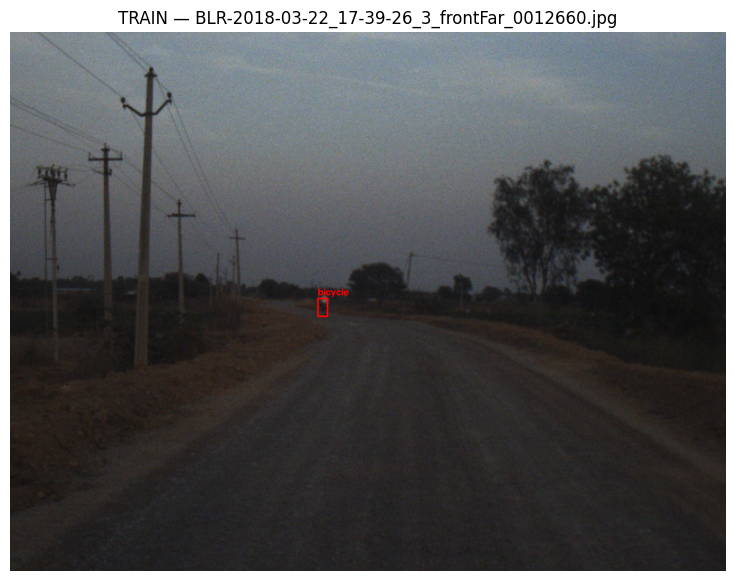

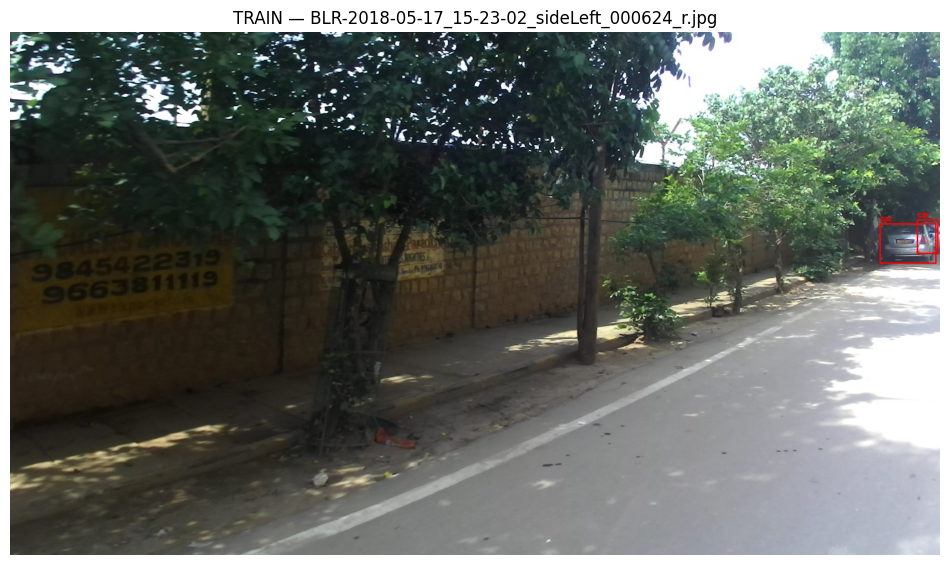

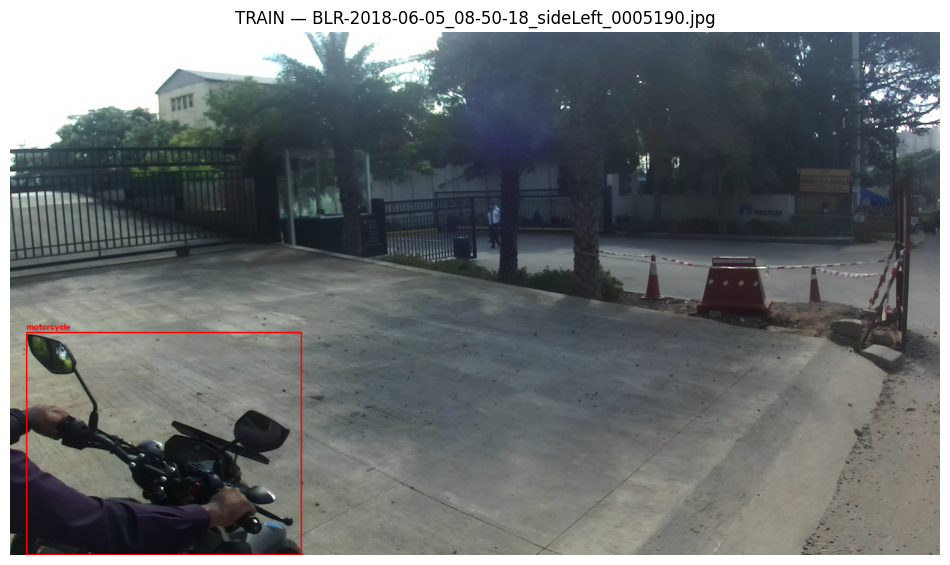

In [ ]:
visualize_random_images(
    split="train",
    num_images=6,
    seed=42
)

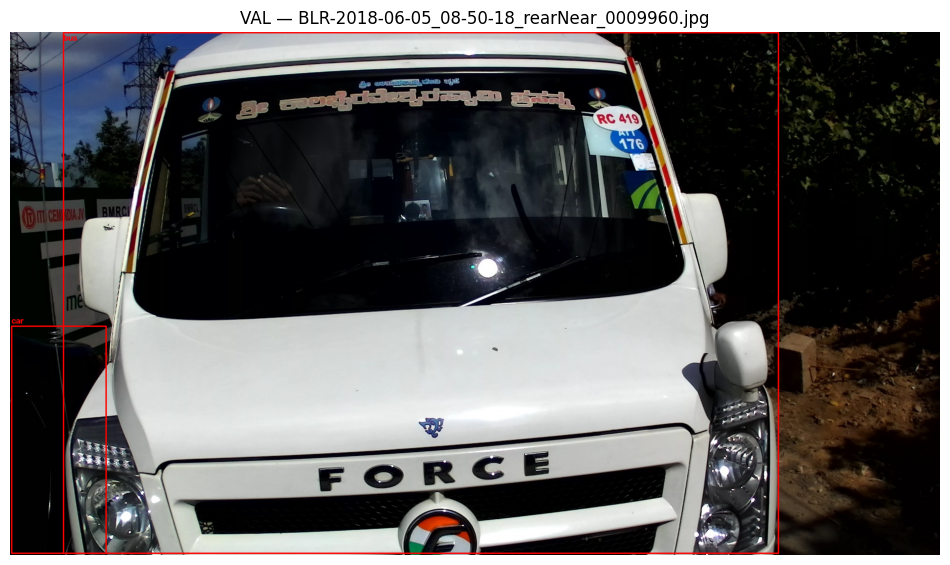

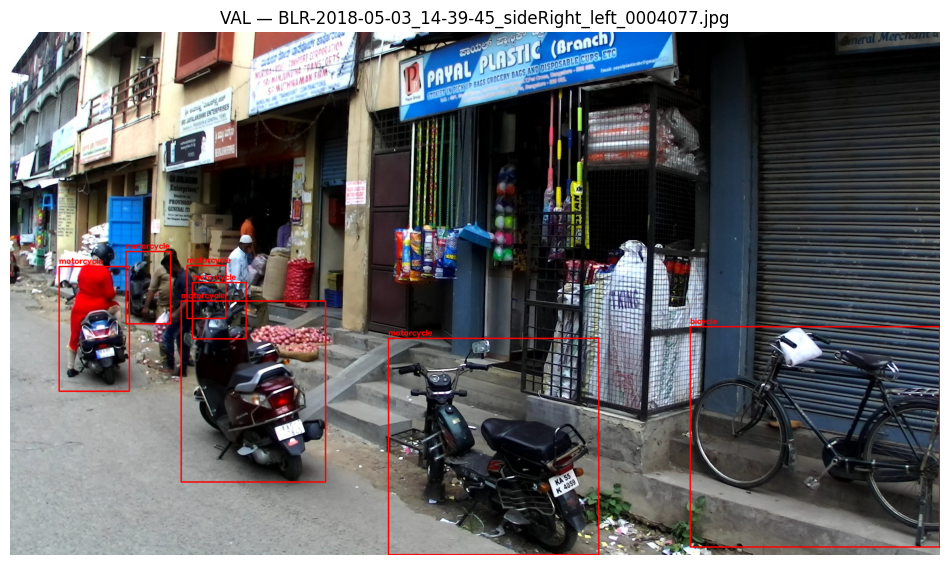

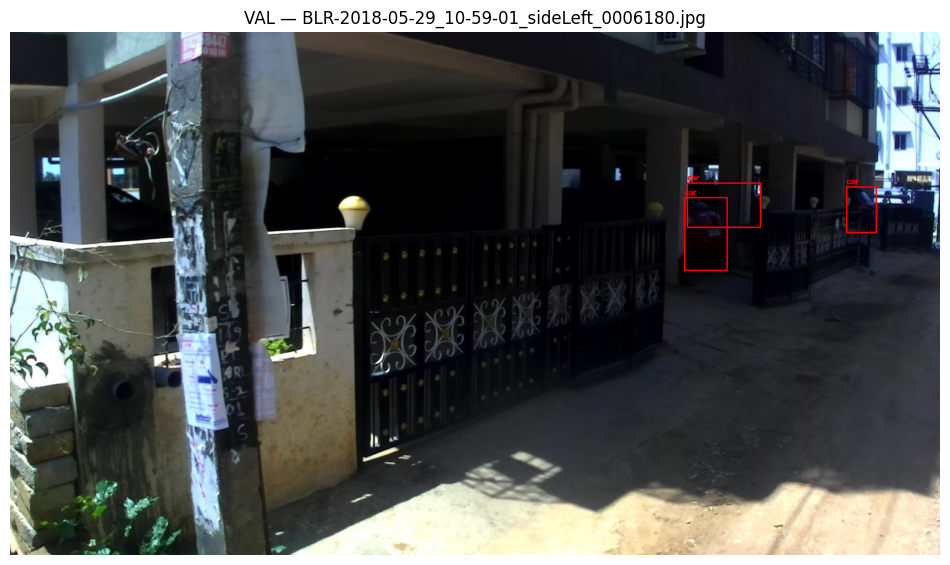

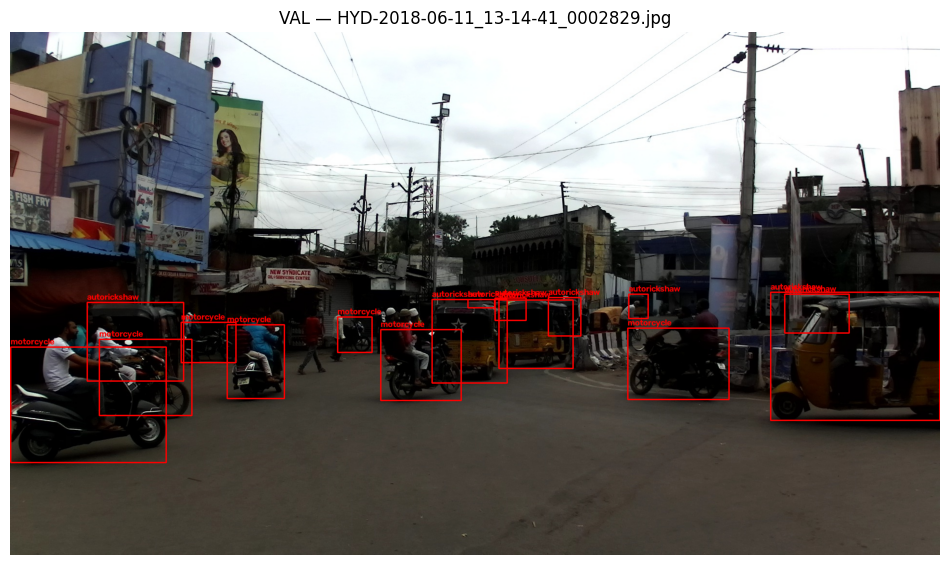

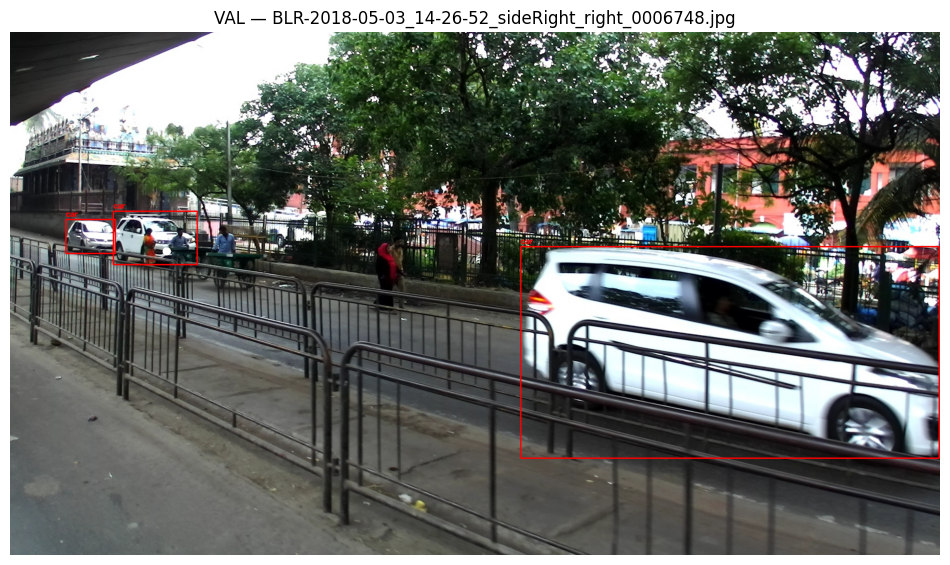

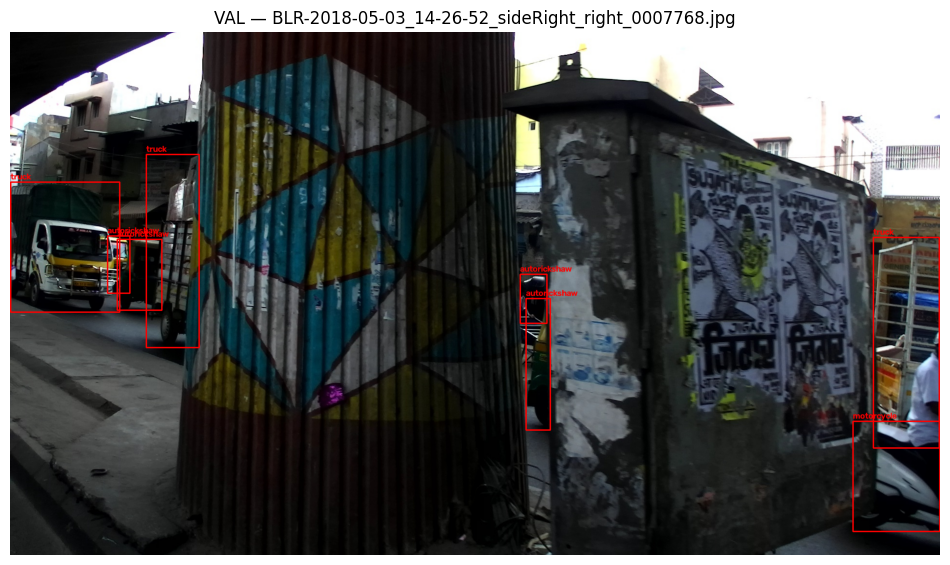

In [ ]:
visualize_random_images(
    split="val",
    num_images=6,
    seed=100
)

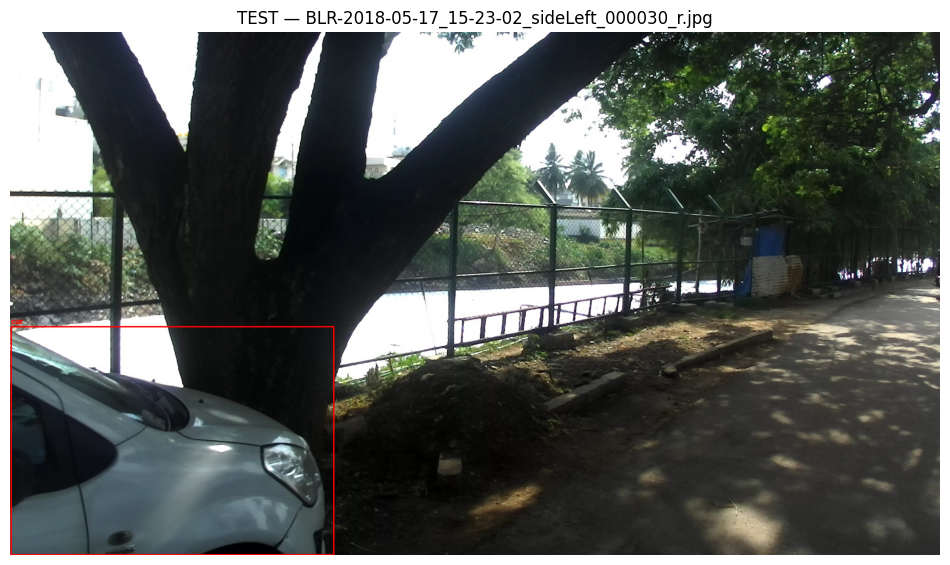

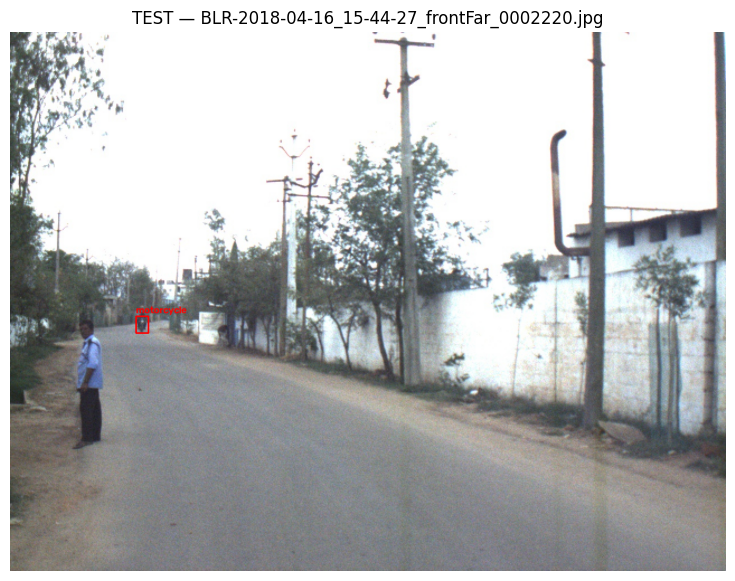

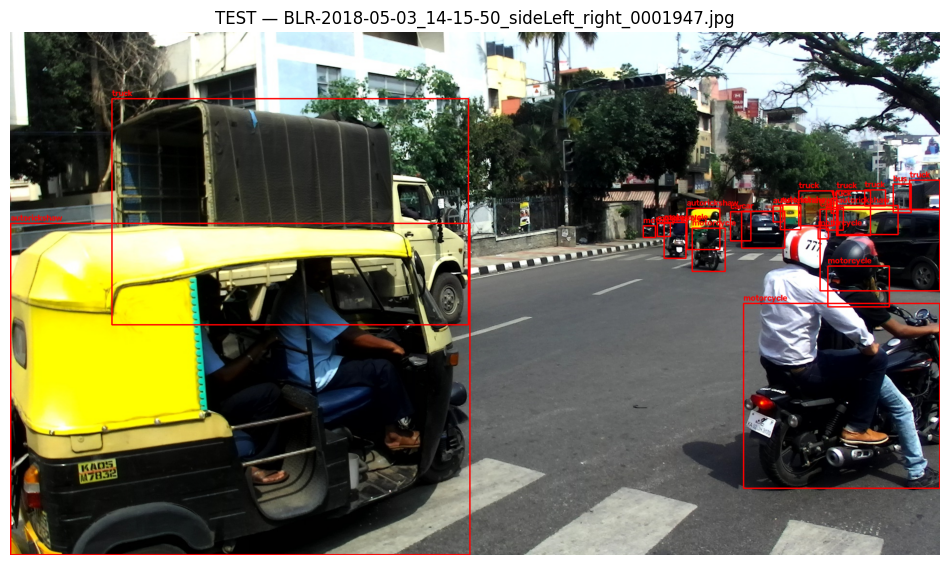

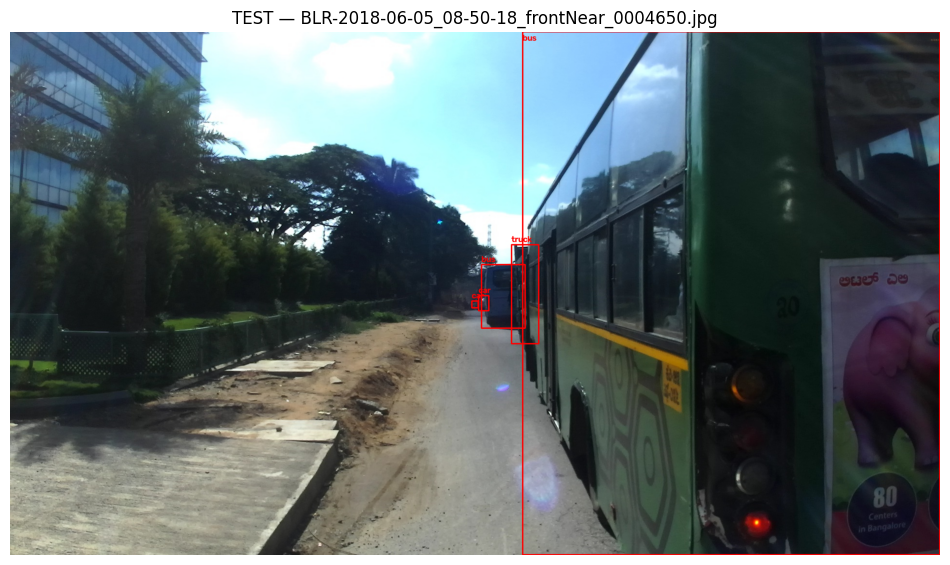

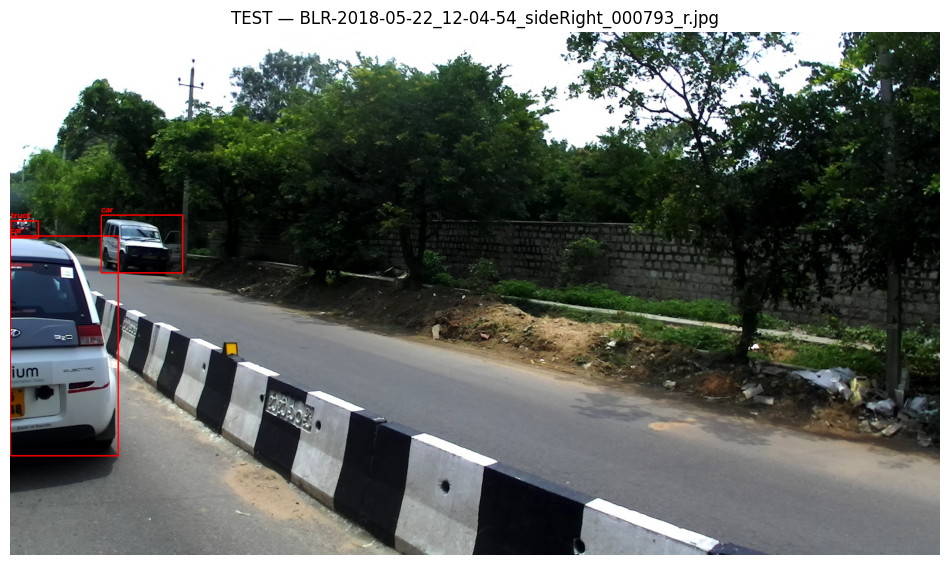

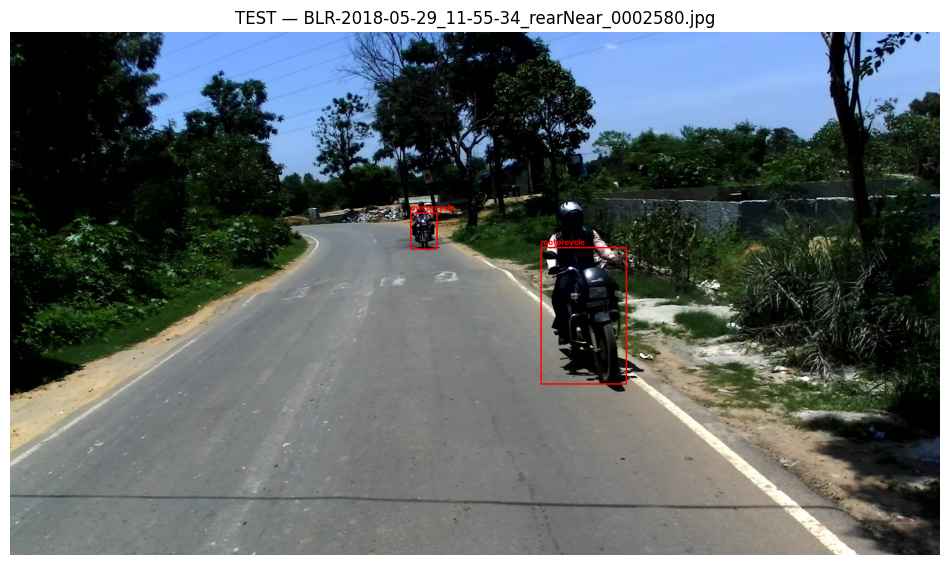

In [ ]:
visualize_random_images(
    split="test",
    num_images=6,
    seed=200
)

In [ ]:
from pathlib import Path

base = Path("/content/final_dataset")

for split in ["train", "val", "test"]:
    images = len(list((base / split / "images").glob("*")))
    labels = len(list((base / split / "labels").glob("*.txt")))

    print(f"{split.upper():5} → Images: {images:,} | Labels: {labels:,}")

TRAIN → Images: 15,000 | Labels: 15,000
VAL   → Images: 2,000 | Labels: 2,000
TEST  → Images: 2,000 | Labels: 2,000


In [ ]:
!du -sh /content/final_dataset

9.5G	/content/final_dataset


In [ ]:
from pathlib import Path

base = Path("/content/final_dataset")

for split in ["train", "val", "test"]:
    images = len(list((base / split / "images").glob("*")))
    labels = len(list((base / split / "labels").glob("*.txt")))

    print(f"{split.upper()}: {images} images | {labels} labels")

TRAIN: 15000 images | 15000 labels
VAL: 2000 images | 2000 labels
TEST: 2000 images | 2000 labels


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp -r /content/final_dataset /content/drive/MyDrive/

In [ ]:
!ls -lh /content/drive/MyDrive/final_dataset

total 13K
-rw------- 1 root root  174 Aug  8 10:47 data.yaml
drwx------ 4 root root 4.0K Aug  8 10:46 test
drwx------ 4 root root 4.0K Aug  8 10:36 train
drwx------ 4 root root 4.0K Aug  8 10:44 val


In [ ]:
from pathlib import Path

drive_dataset = Path("/content/drive/MyDrive/final_dataset")

for split in ["train", "val", "test"]:
    images = len(list((drive_dataset / split / "images").glob("*")))
    labels = len(list((drive_dataset / split / "labels").glob("*.txt")))

    print(f"{split.upper()}: {images} images | {labels} labels")

TRAIN: 15000 images | 15000 labels
VAL: 2000 images | 2000 labels
TEST: 2000 images | 2000 labels


In [ ]:
!tar -czf /content/drive/MyDrive/final_dataset_backup.tar.gz \
    -C /content final_dataset